# Ein erstes Bild erzeugen und anzeigen

## Graustufenbild

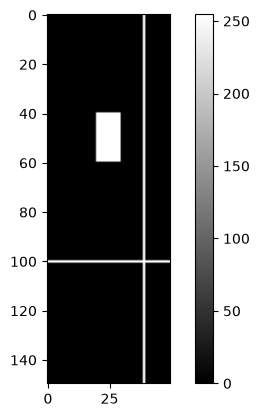

In [23]:
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros( (150,50), dtype=np.uint8 )
img[:, 39] = 255
img[100, :] = 255
img[40:60, 20:30] = 255
plt.imshow( img, cmap="gray" )
plt.colorbar()
plt.show()


In [7]:
type(img)

numpy.ndarray

In [8]:
img.shape

(150, 50)

In [9]:
img.ndim

2

In [25]:
img

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(150, 50), dtype=uint8)

In [24]:
img.dtype

dtype('uint8')

## Farbbild

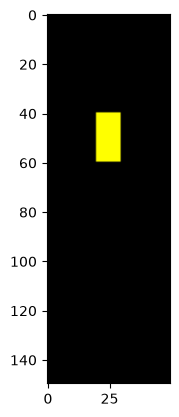

In [57]:
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros( (150,50,3), dtype=np.uint8 )
img[40:60, 20:30, 0 ] = 255
img[40:60, 20:30, 1 ] = 255
img[40:60, 20:30, 2 ] = 0
plt.imshow( img  )
plt.show()

In [53]:
img.shape

(150, 50, 3)

In [54]:
img.dtype

dtype('uint8')

In [55]:
img[0,0,:]

array([0, 0, 0], dtype=uint8)

In [56]:
img.shape[-1] in [3,4]

True

# Ein Bild mit OpenCV einlesen, anzeigen, verändern, speichern

In [1]:
pip show opencv-python

Name: opencv-python
Version: 5.0.0.93
Summary: Wrapper package for OpenCV python bindings.
Home-page: https://github.com/opencv/opencv-python
Author: 
Author-email: 
License: Apache 2.0
Location: /home/juebrauer/miniconda3/envs/env_teaching/lib/python3.12/site-packages
Requires: numpy
Required-by: label-studio-sdk, orbslam3-python, ultralytics
Note: you may need to restart the kernel to use updated packages.


In [3]:
import cv2
cv2.__version__

'5.0.0'

In [4]:
folder = "/home/juebrauer/link_to_vcd/08_datasets/66_test_bilder_dl4cv_ws26"
fname = "campus_hochschule_kempten.png"
abs_path = f"{folder}/{fname}"

img = cv2.imread(abs_path)

In [5]:
type(img)

numpy.ndarray

In [6]:
img.shape

(958, 1490, 3)

In [7]:
img.ndim

3

In [12]:
img.dtype

dtype('uint8')

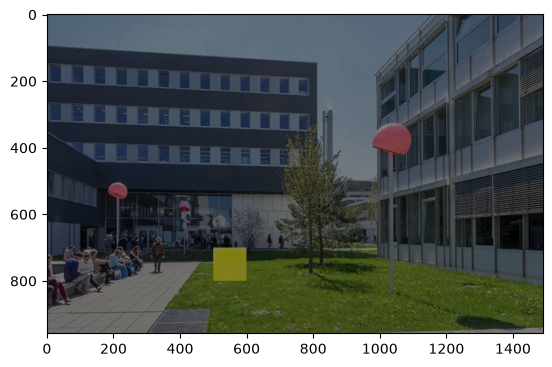

True

In [27]:
import cv2
import matplotlib.pyplot as plt

# 1. Bild einlesen. Achtung: OpenCV nutzt BGR-Farbkanalreihenfolge!
folder = "/home/juebrauer/link_to_vcd/08_datasets/66_test_bilder_dl4cv_ws26"
fname = "campus_hochschule_kempten.png"
abs_path = f"{folder}/{fname}"
img_bgr = cv2.imread(abs_path)

# 2. RGB-Farbkanalreihenfolge für die Anzeige mit Matplotlib vorbereiten
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


# 3. Bild mal modifizieren
img_rgb[700:800, 500:600, 0:2] = 255
img_rgb = img_rgb // 2

# 4. Bild anzeigen
plt.imshow( img_rgb )
#plt.axis("off")
plt.show()

# 5. Bild speichern
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
cv2.imwrite(f"{folder}/modified_{fname}", img_bgr)

In [18]:
img_rgb

-2

In [19]:
type(img_rgb)

int

In [26]:
help(cv2.imwrite)

Help on built-in function imwrite:

imwrite(...)
    imwrite(filename, img[, params]) -> retval
    .   @brief Saves an image to a specified file.
    .
    .   The function imwrite saves the image to the specified file. The image format is chosen based on the
    .   filename extension (see cv::imread for the list of extensions). In general, only 8-bit unsigned (CV_8U)
    .   single-channel or 3-channel (with 'BGR' channel order) images
    .   can be saved using this function, with these exceptions:
    .
    .   - With BMP encoder, 8-bit unsigned (CV_8U) images can be saved.
    .     - BMP images with an alpha channel can be saved using this function.
    .       To achieve this, create an 8-bit 4-channel (CV_8UC4) BGRA image, ensuring the alpha channel is the last component.
    .       Fully transparent pixels should have an alpha value of 0, while fully opaque pixels should have an alpha value of 255.
    .       OpenCV v4.13.0 or later use BI_BITFIELDS compression as default. 

# NumPy `[...,]` Ausdruck verstehen

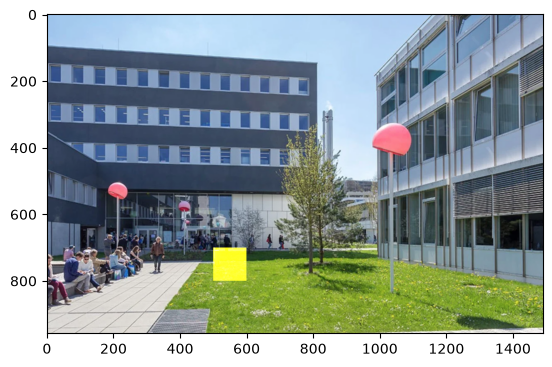

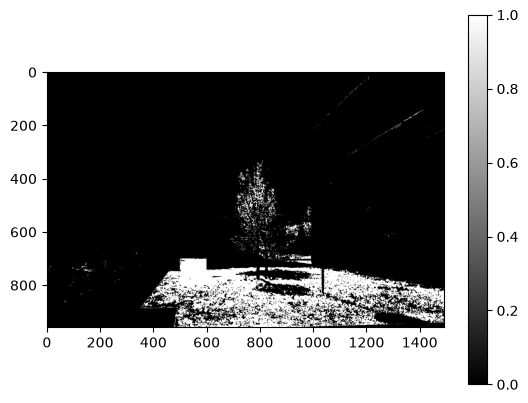

In [10]:
import cv2
import matplotlib.pyplot as plt

# 1. Bild einlesen. Achtung: OpenCV nutzt BGR-Farbkanalreihenfolge!
folder = "/home/juebrauer/link_to_vcd/08_datasets/66_test_bilder_dl4cv_ws26"
fname = "campus_hochschule_kempten.png"
abs_path = f"{folder}/{fname}"
img_bgr = cv2.imread(abs_path)

# 2. RGB-Farbkanalreihenfolge für die Anzeige mit Matplotlib vorbereiten
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


# 3. Bild mal modifizieren
img_rgb[700:800, 500:600, 0:2] = 255
#maske = (img_rgb[..., 0] > 125) & (img_rgb[..., 1] > 125) & (img_rgb[..., 2] < 125)
maske = (img_rgb[:,:, 0] > 125) & (img_rgb[:,:, 1] > 125) & (img_rgb[:,:, 2] < 125)

# 4. Bild anzeigen
plt.imshow( img_rgb )
plt.show()

plt.imshow( maske, cmap="gray" )
plt.colorbar()
plt.show()


In [3]:
img_rgb.shape

(958, 1490, 3)

In [4]:
maske.shape

(958, 1490)

In [5]:
maske.dtype

dtype('bool')

In [6]:
maske[0:5, 0:5]

array([[False, False, False, False, False],
       [False, False, False, False, False],
       [False, False, False, False, False],
       [False, False, False, False, False],
       [False, False, False, False, False]])